# 04 Analitik Asuransi: Rentang Prediksi, Cadangan IBNR, Premi Murni, dan Audit Klaim

Notebook 01-03 menjawab soal kompetisi: berapa klaim lima bulan ke depan, dan faktor apa yang menentukan nilainya. Notebook ini memperluas proyek ke empat pertanyaan yang dihadapi perusahaan asuransi sehari-hari:

| Bagian | Pertanyaan | Dipakai untuk |
|---|---|---|
| 1. Rentang prediksi | Total klaim bulan depan Rp12,9 miliar — paling buruk berapa? | Anggaran dan perencanaan kas |
| 2. Cadangan IBNR | Berapa klaim yang sudah terjadi tetapi belum dibayar? | Cadangan di laporan keuangan |
| 3. Premi murni | Berapa biaya klaim yang wajar per nasabah, menurut plan dan usia? | Penetapan harga polis |
| 4. Audit klaim | Klaim mana yang layak diperiksa ulang? | Pengendalian biaya klaim |

Semua perhitungan ada di `src/asuransi.py`, supaya angka di notebook ini sama dengan file ekspor untuk dashboard.

**Batas data yang perlu diingat sejak awal:** data tidak memuat premi, jadi *loss ratio* (klaim dibagi premi) tidak bisa dihitung. Semua klaim berstatus dibayar, jadi tidak ada label klaim yang ditolak atau terbukti curang.

In [1]:
import sys
import warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src import klaim, asuransi

warnings.filterwarnings("ignore")
pd.set_option("display.float_format", klaim.angka_id)  # angka gaya Indonesia: 1.234,5
plt.rcParams.update({"figure.figsize": (11, 4), "axes.spines.top": False, "axes.spines.right": False})
JUTA, MILIAR = 1e6, 1e9

k = klaim.muat_klaim()
p = klaim.muat_polis()
g = klaim.per_bulan(k)
final = klaim.dikali(klaim.rata_rata(6), 0.95)  # metode final dari notebook 02
BULAN_PREDIKSI = ["2025-08", "2025-09", "2025-10", "2025-11", "2025-12"]

## 1. Rentang prediksi

Notebook 02 menghasilkan satu angka per bulan. Untuk perencanaan, satu angka tidak cukup: bagian keuangan perlu tahu seberapa jauh angka itu bisa meleset.

Rentangnya diambil dari **backtest yang sama** dengan pemilihan metode. Untuk setiap prediksi di backtest, dihitung rasio *aktual ÷ prediksi*. Sebaran rasio ini menunjukkan seberapa jauh metode final biasanya meleset, lalu dipakai untuk melebarkan prediksi final.

In [2]:
rasio = asuransi.rasio_backtest(g, final)
print(f"Jumlah rasio per target: {rasio.groupby('target').size().iloc[0]} (9 titik awal x 5 bulan ke depan)")
(rasio.groupby("target")["rasio"].quantile([0.1, 0.5, 0.9]).unstack()
      .rename(columns={0.1: "persentil 10", 0.5: "median", 0.9: "persentil 90"})
      .loc[klaim.TARGET].map(lambda v: klaim.angka_id(v, 3)))

Jumlah rasio per target: 45 (9 titik awal x 5 bulan ke depan)


,persentil 10,median,persentil 90
target,,,
Claim_Frequency,"0,901","1,023","1,161"
Claim_Severity,"0,880","1,035","1,306"
Total_Claim,"0,832","1,019","1,304"


In [3]:
rentang = asuransi.rentang_prediksi(g, final, rasio, BULAN_PREDIKSI)
agustus = rentang[rentang.bulan == "2025-08"].set_index("target").loc[klaim.TARGET]
skala = pd.Series({"Claim_Frequency": 1, "Claim_Severity": JUTA, "Total_Claim": MILIAR})
tampil = agustus[["batas_bawah", "prediksi", "median", "batas_atas"]].div(skala, axis=0)
tampil.index = ["Frekuensi (klaim)", "Severity (Rp juta)", "Total (Rp miliar)"]
tampil.columns = ["batas bawah (P10)", "prediksi kompetisi", "median", "batas atas (P90)"]
tampil

,batas bawah (P10),prediksi kompetisi,median,batas atas (P90)
Frekuensi (klaim),"202,7","225,0","230,3","261,2"
Severity (Rp juta),"48,0","54,5","56,4","71,2"
Total (Rp miliar),"10,7","12,9","13,2","16,8"


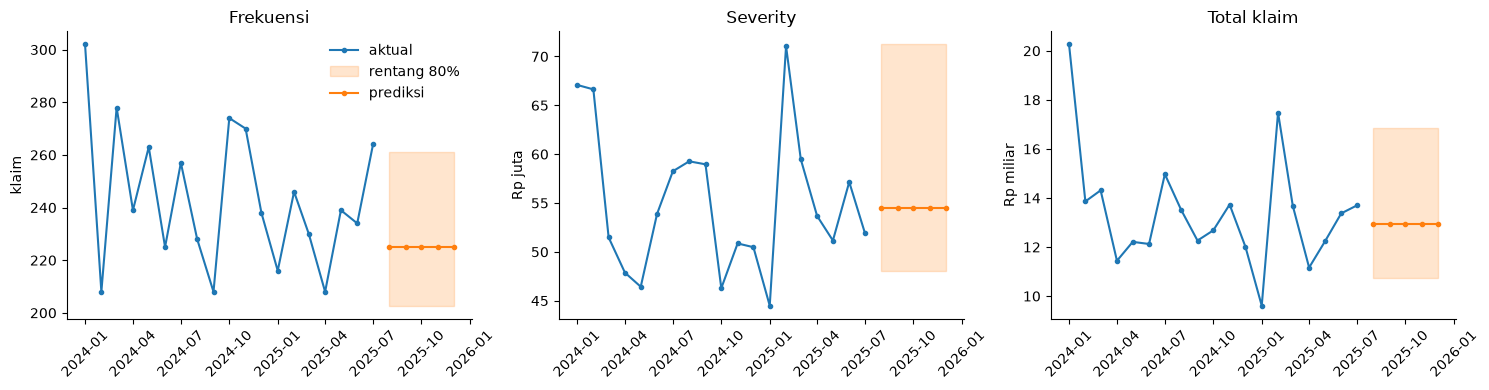

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
judul = {"Claim_Frequency": ("Frekuensi", 1, "klaim"),
         "Claim_Severity": ("Severity", JUTA, "Rp juta"),
         "Total_Claim": ("Total klaim", MILIAR, "Rp miliar")}
x_hist = g.index.to_timestamp()
x_pred = pd.PeriodIndex(BULAN_PREDIKSI, freq="M").to_timestamp()
for ax, t in zip(axes, klaim.TARGET):
    nama, s, satuan = judul[t]
    r = rentang[rentang.target == t]
    ax.plot(x_hist, g[t] / s, color="C0", marker="o", ms=3, label="aktual")
    ax.fill_between(x_pred, r.batas_bawah / s, r.batas_atas / s, color="C1", alpha=0.2, label="rentang 80%")
    ax.plot(x_pred, r.prediksi / s, color="C1", marker="o", ms=3, label="prediksi")
    ax.set_title(nama)
    ax.set_ylabel(satuan)
    ax.tick_params(axis="x", rotation=45)
axes[0].legend(frameon=False)
plt.tight_layout()
plt.show()

**Apakah rentangnya bisa dipercaya?** Rentang 80% seharusnya menangkap sekitar 80% kejadian. Pengujiannya dilakukan secara jujur: untuk setiap titik awal backtest, rentang dihitung **tanpa** titik itu, lalu dicek apakah nilai aktualnya masuk.

In [5]:
asuransi.cakupan_interval(rasio).map(klaim.persen_id).to_frame("tercakup dalam rentang 80%")

,tercakup dalam rentang 80%
Claim_Frequency,"75,6%"
Claim_Severity,"75,6%"
Total_Claim,"75,6%"


Rentangnya menangkap 76% kasus, sedikit di bawah target 80%. Rentang ini sedikit terlalu sempit, wajar karena hanya dihitung dari 45 rasio yang saling tumpang tindih. Untuk dipakai sungguhan, batasnya sebaiknya diperlebar sedikit, misalnya memakai persentil 5 sampai 95.

**Temuan penting: rentangnya tidak simetris.** Batas atas total klaim sekitar 30% di atas prediksi, sedangkan batas bawahnya hanya 17% di bawah. Penyebabnya klaim raksasa: satu bulan bisa melonjak karena beberapa klaim rawat inap di luar negeri, tetapi tidak pernah "anjlok" dengan cara yang sama.

**Prediksi kompetisi bukan angka yang tepat untuk anggaran.** Faktor 0,95 sengaja menurunkan prediksi karena MAPE lebih menghukum prediksi yang terlalu tinggi. Untuk anggaran, angka yang lebih tepat adalah median (sekitar Rp13,2 miliar per bulan). Untuk menyiapkan kas menghadapi bulan buruk, angka yang tepat adalah batas atas (sekitar Rp16,8 miliar). **Metrik penilaian menentukan angka mana yang "benar"** — dan kebutuhan bisnis yang menentukan metriknya.

## 2. Cadangan IBNR

Klaim tidak dibayar saat terjadi. Pasien masuk rumah sakit, pulang, mengajukan klaim, lalu klaim diperiksa dan dibayar. Selama jeda itu, perusahaan sudah berutang tetapi belum mengeluarkan uang.

Klaim yang **sudah terjadi tetapi belum dibayar** harus dicadangkan di laporan keuangan. Dalam istilah asuransi disebut **IBNR** (*incurred but not reported*) — di sini lebih tepatnya "terjadi tetapi belum dibayar", karena data tidak memuat tanggal klaim dilaporkan.

Seberapa lama jedanya:

Klaim tanpa tanggal bayar: 37 (tidak bisa masuk segitiga, dibahas di bagian 4)


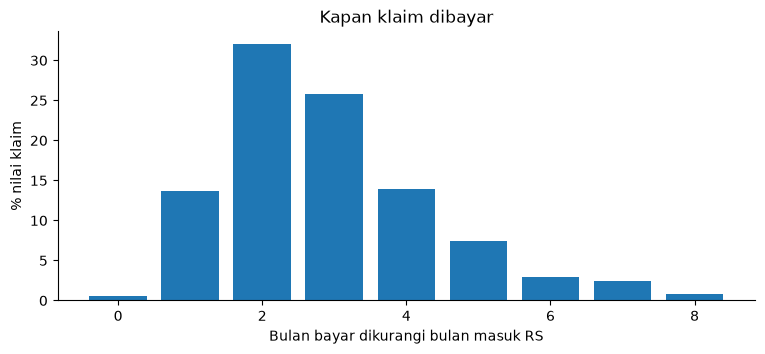

Dibayar di bulan yang sama: 0,6% | dalam 3 bulan: 72,1% | 6 bulan atau lebih: 6,4%


In [6]:
d = asuransi.siapkan_pembayaran(k)
print(f"Klaim tanpa tanggal bayar: {len(k) - len(d)} (tidak bisa masuk segitiga, dibahas di bagian 4)")

porsi = d.groupby("umur")[klaim.NILAI].sum() / d[klaim.NILAI].sum()
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.bar(porsi.index[:9], porsi.values[:9] * 100, color="C0")
ax.set_xlabel("Bulan bayar dikurangi bulan masuk RS")
ax.set_ylabel("% nilai klaim")
ax.set_title("Kapan klaim dibayar")
plt.show()
print(f"Dibayar di bulan yang sama: {klaim.persen_id(porsi.get(0, 0))} | "
      f"dalam 3 bulan: {klaim.persen_id(porsi.loc[:3].sum())} | 6 bulan atau lebih: {klaim.persen_id(porsi.loc[6:].sum())}")

Hampir tidak ada klaim yang dibayar di bulan kejadiannya, dan sebagian besar baru lunas dua sampai tiga bulan kemudian. Artinya, pada akhir bulan mana pun, klaim tiga bulan terakhir selalu belum lengkap.

### Segitiga pengembangan

Alat standar untuk menghitung cadangan adalah **segitiga pengembangan**: baris adalah bulan kejadian, kolom adalah umur (berapa bulan sejak kejadian), dan isinya total yang sudah dibayar sampai umur itu. Bentuknya segitiga karena bulan yang lebih baru belum sempat mencapai umur yang lebih tua.

Untuk menguji metodenya secara jujur, posisinya dibuat **seolah-olah sekarang 31 Juli 2025**: hanya pembayaran sampai tanggal itu yang terlihat. Estimasinya lalu dibandingkan dengan pembayaran yang benar-benar terjadi sampai Desember 2025.

In [7]:
VALUASI = "2025-07"
kum = asuransi.segitiga_kumulatif(d, VALUASI)
tampil = (kum / MILIAR).iloc[-12:, :8]
tampil.index = tampil.index.astype(str)
tampil.columns = [f"umur {c}" for c in tampil.columns]
tampil.style.format(lambda v: "" if pd.isna(v) else klaim.angka_id(v, 2)).set_caption(
    "Pembayaran kumulatif (Rp miliar), posisi 31 Juli 2025, 12 bulan terakhir")

,umur 0,umur 1,umur 2,umur 3,umur 4,umur 5,umur 6,umur 7
2024-08,"0,00","1,16","5,04","9,29","9,70","12,06","12,06","13,51"
2024-09,"0,00","0,20","6,02","9,82","10,36","10,44","12,26","12,26"
2024-10,"0,01","3,08","9,33","11,86","12,16","12,68","12,68","12,68"
2024-11,"0,16","3,07","9,67","12,30","13,48","13,72","13,73","13,73"
2024-12,"0,06","3,35","7,59","9,28","10,17","11,54","12,01","12,01"
2025-01,"0,19","1,61","7,46","8,34","8,56","8,64","9,61",
2025-02,"0,01","2,33","5,40","9,38","15,72","17,45",,
2025-03,"0,01","2,43","5,83","8,70","13,41",,,
2025-04,"0,03","0,68","5,36","8,95",,,,
2025-05,"0,00","1,21","6,72",,,,,


**Chain-ladder** — metode paling dasar — menghitung rata-rata pertumbuhan dari satu umur ke umur berikutnya pada bulan-bulan lama, lalu menerapkannya pada bulan-bulan baru.

Kelemahannya terlihat di baris terakhir: sampai 31 Juli, belum ada pembayaran untuk klaim bulan Juli. Nol dikalikan faktor apa pun tetap nol.

**Bornhuetter-Ferguson** memperbaikinya. Untuk bagian yang belum dibayar, metode ini tidak mengalikan pembayaran yang ada, tetapi memakai **patokan awal**: rata-rata nilai akhir bulan-bulan yang sudah lengkap. Patokan itu pada dasarnya metode rata-rata yang sama dengan notebook 02, jadi bagian forecasting dan cadangan saling tersambung.

In [8]:
est = asuransi.estimasi_ultimate(kum, VALUASI)
akhir = d.groupby("bulan")[klaim.NILAI].sum()
banding = est.tail(6).assign(aktual=akhir.reindex(est.tail(6).index).values)
tabel = (banding[["dibayar", "ultimate_CL", "ultimate_BF", "aktual"]] / MILIAR)
tabel.index = tabel.index.astype(str)
tabel.columns = ["dibayar per 31 Jul", "estimasi chain-ladder", "estimasi BF", "aktual (s.d. Des 2025)"]
tabel

,dibayar per 31 Jul,estimasi chain-ladder,estimasi BF,aktual (s.d. Des 2025)
2025-02,"17,5","19,3","18,7","17,5"
2025-03,"13,4","16,6","15,8","13,7"
2025-04,"9,0","13,6","13,2","10,9"
2025-05,"6,7","16,2","14,0","11,9"
2025-06,"2,1","17,0","13,0","12,3"
2025-07,"0,0","0,9","12,4","13,2"


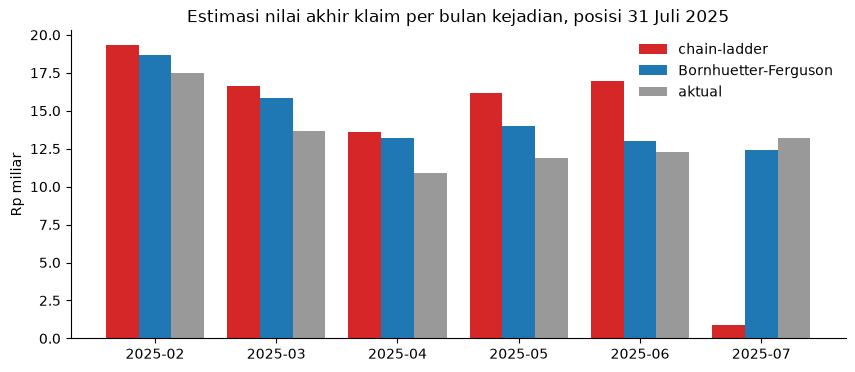

In [9]:
fig, ax = plt.subplots(figsize=(10, 4))
x = np.arange(len(tabel))
lebar = 0.27
ax.bar(x - lebar, tabel.iloc[:, 1], lebar, label="chain-ladder", color="C3")
ax.bar(x, tabel.iloc[:, 2], lebar, label="Bornhuetter-Ferguson", color="C0")
ax.bar(x + lebar, tabel.iloc[:, 3], lebar, label="aktual", color="0.6")
ax.set_xticks(x, tabel.index)
ax.set_ylabel("Rp miliar")
ax.set_title("Estimasi nilai akhir klaim per bulan kejadian, posisi 31 Juli 2025")
ax.legend(frameon=False)
plt.show()

Satu tanggal valuasi bisa kebetulan. Pengujiannya diulang di **sepuluh tanggal valuasi** (Oktober 2024 sampai Juli 2025), masing-masing untuk enam bulan kejadian terakhir:

In [10]:
uji = asuransi.uji_ibnr(d, pd.period_range("2024-10", "2025-07", freq="M"))
error = uji.assign(cl=uji.error_CL.abs(), bf=uji.error_BF.abs()).groupby("umur")[["cl", "bf"]].median()
error.columns = ["chain-ladder", "Bornhuetter-Ferguson"]
error.index.name = "umur bulan kejadian (bulan)"
error.map(klaim.persen_id)

,chain-ladder,Bornhuetter-Ferguson
umur bulan kejadian (bulan),,
0,"93,9%","10,9%"
1,"46,7%","12,2%"
2,"48,7%","27,5%"
3,"23,6%","21,4%"
4,"16,4%","15,3%"
5,"5,8%","5,9%"


Untuk bulan yang paling baru (umur 0 dan 1), chain-ladder meleset 47-94%, sedangkan Bornhuetter-Ferguson hanya 11-12%. Begitu bulan kejadian semakin tua dan pembayarannya hampir lengkap, kedua metode semakin mirip.

**Tetapi lihat totalnya** — ini jebakan yang perlu diwaspadai:

In [11]:
v = uji[uji.valuasi == VALUASI]
pd.Series({
    "IBNR aktual": (v.aktual - v.dibayar).sum(),
    "IBNR chain-ladder": (v.ultimate_CL - v.dibayar).sum(),
    "IBNR Bornhuetter-Ferguson": (v.ultimate_BF - v.dibayar).sum(),
}).div(MILIAR).to_frame("Rp miliar, enam bulan terakhir")

,"Rp miliar, enam bulan terakhir"
IBNR aktual,"30,8"
IBNR chain-ladder,"34,9"
IBNR Bornhuetter-Ferguson,"38,5"


Untuk total IBNR, chain-ladder terlihat **lebih dekat** dengan aktual. Tetapi itu kebetulan: kelebihan besarnya di Mei dan Juni tertutup oleh kekurangan hampir Rp12,4 miliar di Juli. Kalau hanya melihat total, kita akan memilih metode yang salah.

Kedua metode juga sama-sama **kelebihan** di bulan berumur 2-4. Penyebabnya terlihat di sini:

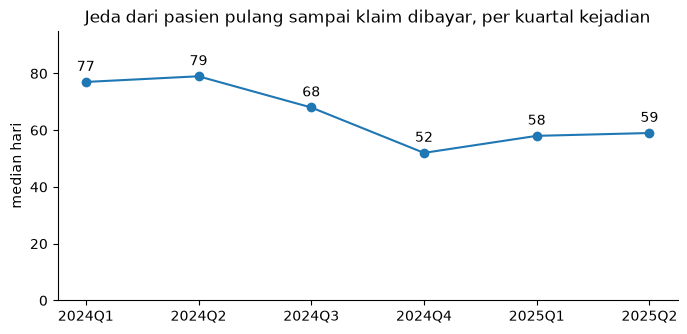

In [12]:
lengkap = d[d["bulan"] <= "2025-06"].copy()
lengkap["jeda_hari"] = (lengkap[asuransi.TGL_BAYAR] - lengkap[asuransi.TGL_KELUAR]).dt.days
per_kuartal = lengkap.groupby(lengkap["bulan"].dt.asfreq("Q"))["jeda_hari"].median()

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(per_kuartal.index.astype(str), per_kuartal.values, marker="o", color="C0")
for i, v in enumerate(per_kuartal.values):
    ax.annotate(f"{v:.0f}", (i, v), textcoords="offset points", xytext=(0, 8), ha="center")
ax.set_ylabel("median hari")
ax.set_ylim(0, 95)
ax.set_title("Jeda dari pasien pulang sampai klaim dibayar, per kuartal kejadian")
plt.show()

**Pembayaran klaim makin cepat.** Median jedanya turun dari sekitar 77-79 hari di awal 2024 menjadi 52-59 hari sejak akhir 2024.

Chain-ladder mengasumsikan kecepatan pembayaran tetap. Faktornya dihitung dari bulan-bulan lama yang pembayarannya lebih lambat, sehingga ketika diterapkan pada bulan-bulan baru yang sudah lebih banyak terbayar, estimasinya kebesaran. Bornhuetter-Ferguson ikut terpengaruh karena memakai faktor yang sama untuk menentukan porsi yang belum dibayar.

Dalam praktik, aktuaris menangani ini dengan menghitung faktor hanya dari periode terbaru, atau menyesuaikannya secara manual. Di data ini, periode "baru" baru berjalan sekitar tiga kuartal — terlalu pendek untuk menghitung faktor yang stabil.

**Catatan penting soal nilai "aktual":** data pembayaran berhenti di Desember 2025, jadi klaim Juni dan Juli 2025 baru teramati enam dan lima bulan. Padahal 6,4% nilai klaim baru dibayar enam bulan atau lebih setelah kejadian — porsinya jauh lebih besar dari porsi jumlah klaim (sekitar 1,5%), karena klaim yang lama diproses cenderung bernilai besar. Artinya, nilai aktual dua bulan terakhir kemungkinan masih kurang beberapa persen dari nilai akhir sebenarnya, dan sebagian "error" estimasi di bulan-bulan itu bisa jadi bukan kesalahan metode.

## 3. Premi murni

**Premi murni** adalah biaya klaim yang diharapkan per nasabah per tahun, sebelum ditambah biaya operasional dan keuntungan. Rumus standarnya memisahkan dua hal:

> premi murni = frekuensi (berapa kali klaim per tahun) × severity (berapa nilai per klaim)

Keduanya dimodelkan dengan **GLM** (*generalized linear model*), metode yang paling banyak dipakai untuk tarif asuransi. GLM dipilih karena hasilnya berupa **pengali** yang mudah dijelaskan: "nasabah usia 70+ klaim 1,5 kali lebih sering daripada usia 50-59."

**Hanya informasi yang diketahui saat polis dijual** yang boleh menjadi faktor tarif: plan, usia, gender, dan domisili. Lokasi rumah sakit dan diagnosis memang sangat menentukan nilai klaim (notebook 03), tetapi baru diketahui setelah klaim terjadi, jadi tidak bisa dipakai untuk menetapkan harga.

In [13]:
polis = asuransi.siapkan_polis(p, k)
print(f"Polis: {klaim.angka_id(len(polis), 0)} | pernah klaim: {klaim.persen_id((polis.n_klaim > 0).mean())} | "
      f"klaim terbanyak satu polis: {polis.n_klaim.max():.0f}")
print(f"Rata-rata klaim per polis (19 bulan): {klaim.angka_id(polis.n_klaim.mean(), 2)} | "
      f"varians: {klaim.angka_id(polis.n_klaim.var(), 1)}")

Polis: 4.096 | pernah klaim: 29,5% | klaim terbanyak satu polis: 222
Rata-rata klaim per polis (19 bulan): 1,13 | varians: 30,5


### Frekuensi: kenapa bukan Poisson

Model hitungan yang paling dasar adalah **Poisson**, yang mengasumsikan varians sama dengan rata-rata. Di data ini variansnya puluhan kali rata-ratanya: kebanyakan nasabah tidak pernah klaim, sedangkan segelintir nasabah klaim puluhan sampai ratusan kali (kemungkinan pasien penyakit kronis yang berobat rutin).

Kalau Poisson tetap dipakai, model akan terlalu yakin — semua faktor terlihat signifikan padahal tidak. **Negative Binomial** menambahkan satu parameter untuk menampung sebaran yang lebar ini.

In [14]:
import statsmodels.api as sm
import statsmodels.formula.api as smf

poisson = smf.glm(f"n_klaim ~ {asuransi.RUMUS_FAKTOR}", polis, family=sm.families.Poisson(),
                  exposure=polis["eksposur"]).fit()
frek = asuransi.latih_frekuensi(polis)
print(f"Poisson: rasio dispersi {klaim.angka_id(poisson.pearson_chi2 / poisson.df_resid, 1)} "
      f"(seharusnya sekitar 1), AIC {klaim.angka_id(poisson.aic, 0)}")
print(f"Negative Binomial: AIC {klaim.angka_id(frek.aic, 0)} (lebih kecil lebih baik)")

Poisson: rasio dispersi 26,2 (seharusnya sekitar 1), AIC 19.968


Negative Binomial: AIC 9.815 (lebih kecil lebih baik)


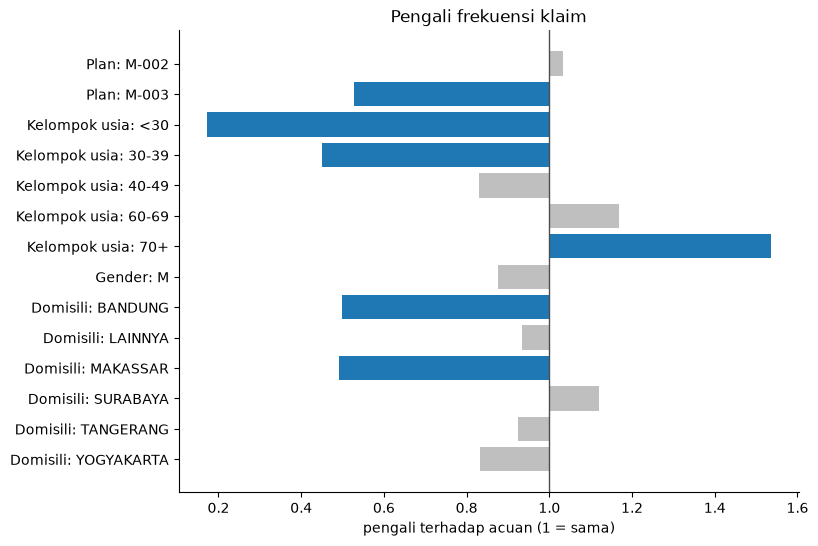

Acuan: plan M-001, usia 50-59, perempuan, Jakarta. Abu-abu = tidak signifikan (p >= 0,05).


In [15]:
NAMA = {"plan": "Plan", "kel_usia": "Kelompok usia", "gender": "Gender", "domisili": "Domisili"}


def gambar_pengali(rel, judul, ax):
    rel = rel.iloc[::-1]
    warna = ["C0" if p < 0.05 else "0.75" for p in rel.p_value]
    ax.barh(rel.faktor + ": " + rel.level, rel.pengali - 1, left=1, color=warna)
    ax.axvline(1, color="0.3", linewidth=1)
    ax.set_title(judul)
    ax.set_xlabel("pengali terhadap acuan (1 = sama)")


rel_frek = asuransi.relativitas(frek, NAMA)
fig, ax = plt.subplots(figsize=(8, 6))
gambar_pengali(rel_frek, "Pengali frekuensi klaim", ax)
plt.show()
print("Acuan: plan M-001, usia 50-59, perempuan, Jakarta. Abu-abu = tidak signifikan (p >= 0,05).")

**Usia** adalah faktor frekuensi terkuat dan polanya masuk akal: nasabah di bawah 30 tahun klaim kurang dari seperlima kali kelompok 50-59, sedangkan usia 70 ke atas sekitar 1,5 kali. **Plan M-003** klaim sekitar separuh lebih jarang daripada M-001. Nasabah di **Bandung** dan **Makassar** juga klaim sekitar separuh lebih jarang daripada Jakarta.

**Gender** tidak signifikan, jadi tidak ada alasan dari data untuk membedakan tarif menurut gender. Di beberapa wilayah, misalnya Uni Eropa, pembedaan tarif menurut gender memang dilarang.

### Severity

Severity dimodelkan dengan GLM **Gamma**, yang cocok untuk nilai positif yang miring ke kanan. Klaim di atas persentil 99 (sekitar Rp634 juta) dipotong lebih dulu: satu klaim bernilai miliaran bisa menyeret koefisien seluruh segmennya. Bagian yang terpotong dikembalikan lewat **faktor beban klaim besar** yang sama untuk semua nasabah.

Batas potong: Rp634 juta | faktor beban klaim besar: 1,073 (bagian di atas batas = 6,8% nilai klaim)


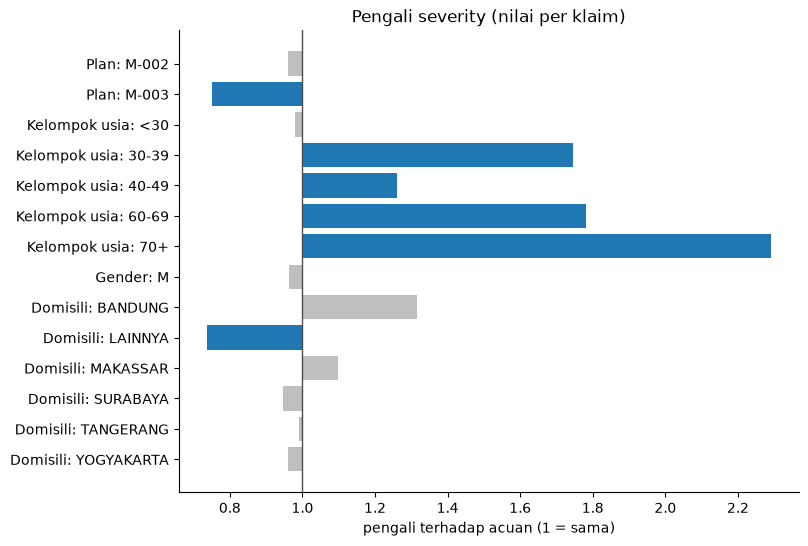

In [16]:
klaim_polis = k.merge(polis[["Nomor Polis", "plan", "kel_usia", "gender", "domisili"]], on="Nomor Polis")
sev, batas, beban = asuransi.latih_severity(klaim_polis)
print(f"Batas potong: Rp{klaim.angka_id(batas / JUTA, 0)} juta | faktor beban klaim besar: "
      f"{klaim.angka_id(beban, 3)} (bagian di atas batas = {klaim.persen_id(1 - 1 / beban)} nilai klaim)")

fig, ax = plt.subplots(figsize=(8, 6))
gambar_pengali(asuransi.relativitas(sev, NAMA), "Pengali severity (nilai per klaim)", ax)
plt.show()

Severity lebih sulit diprediksi daripada frekuensi, dan sebagian besar faktornya tidak signifikan. Dua yang jelas:

- **Plan M-003** punya severity sekitar seperempat lebih rendah. Ini konsisten dengan notebook 03: semua klaim M-003 terjadi di Indonesia, sedangkan separuh klaim M-001 di Singapura.
- **Usia 60 ke atas** punya severity sekitar 1,8 sampai 2,3 kali kelompok 50-59.

Kelompok 30-39 juga tampak tinggi, tetapi polanya tidak naik bertahap seperti kelompok tua, jadi kemungkinan besar dipengaruhi segelintir klaim besar. Faktor seperti ini dalam praktik akan diperiksa ulang atau digabung dengan kelompok sebelahnya sebelum dipakai untuk tarif.

### Premi murni per segmen

In [17]:
polis["premi_murni"] = asuransi.premi_murni(polis, frek, sev, beban)
tabel = polis.pivot_table(index="kel_usia", columns="plan", values="premi_murni", aggfunc="mean") / JUTA
tabel = tabel.reindex(asuransi.LABEL_USIA)
tabel.style.format(lambda v: klaim.angka_id(v, 1)).background_gradient(cmap="Blues", axis=None).set_caption(
    "Premi murni rata-rata (Rp juta per nasabah per tahun)")

plan,M-001,M-002,M-003
kel_usia,,,
<30,"5,5","5,8","2,5"
30-39,"27,4","27,1","11,9"
40-49,"34,9","36,5","15,3"
50-59,"33,3","34,7","14,4"
60-69,"71,2","71,4","30,3"
70+,"121,2","120,8","51,3"


Tabel ini adalah inti tarif: nasabah plan M-001 usia 70+ "wajar" dibebani biaya klaim sekitar sepuluh kali nasabah M-003 usia 30-an. Kelompok 40-49 sedikit di atas 50-59 karena pengali severity-nya lebih tinggi — pola yang perlu diperiksa ulang sebelum dipakai. Premi sebenarnya ditambah biaya operasional, komisi, dan margin di atas angka ini.

### Apakah model membedakan risiko dengan benar?

Model yang dilatih dan dinilai di data yang sama akan selalu terlihat bagus. Maka 20% polis disisihkan, model dilatih ulang dengan 80% sisanya, lalu polis uji diurutkan dari prediksi paling murah ke paling mahal dan dibagi menjadi sepuluh kelompok. Model yang baik menunjukkan **biaya aktual yang naik** seiring naiknya prediksi.

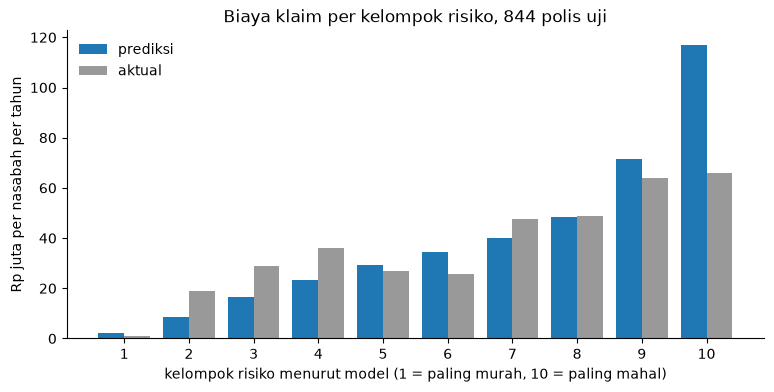

20% polis yang dinilai paling berisiko menyumbang 35,7% biaya klaim aktual
Total prediksi dibagi total aktual di polis uji: 1,08


In [18]:
rng = np.random.default_rng(42)
uji_mask = rng.random(len(polis)) < 0.2
latih, tes = polis[~uji_mask], polis[uji_mask].copy()

frek_l = asuransi.latih_frekuensi(latih)
sev_l, _, beban_l = asuransi.latih_severity(klaim_polis[klaim_polis["Nomor Polis"].isin(latih["Nomor Polis"])])
tes["prediksi"] = asuransi.premi_murni(tes, frek_l, sev_l, beban_l)
tes["aktual"] = tes["biaya"] / tes["eksposur"]
tes["desil"] = pd.qcut(tes["prediksi"].rank(method="first"), 10, labels=range(1, 11))
lift = tes.groupby("desil", observed=True)[["prediksi", "aktual"]].mean() / JUTA

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(lift.index.astype(int) - 0.2, lift["prediksi"], 0.4, label="prediksi", color="C0")
ax.bar(lift.index.astype(int) + 0.2, lift["aktual"], 0.4, label="aktual", color="0.6")
ax.set_xticks(range(1, 11))
ax.set_xlabel("kelompok risiko menurut model (1 = paling murah, 10 = paling mahal)")
ax.set_ylabel("Rp juta per nasabah per tahun")
ax.set_title(f"Biaya klaim per kelompok risiko, {klaim.angka_id(len(tes), 0)} polis uji")
ax.legend(frameon=False)
plt.show()

atas = tes.nlargest(int(len(tes) * 0.2), "prediksi")
print(f"20% polis yang dinilai paling berisiko menyumbang {klaim.persen_id(atas['biaya'].sum() / tes['biaya'].sum())} biaya klaim aktual")
print(f"Total prediksi dibagi total aktual di polis uji: {klaim.angka_id(tes['prediksi'].sum() / tes['aktual'].sum(), 2)}")

**Model bisa memisahkan risiko rendah dan tinggi.** Kelompok paling murah menurut model biaya aktualnya hanya sekitar Rp1 juta per nasabah per tahun, sedangkan kelompok 9-10 sekitar Rp65 juta. Seperlima polis yang dinilai paling berisiko menyumbang lebih dari sepertiga biaya klaim aktual.

**Tetapi ada dua kelemahan yang harus diakui:**

- **Kelompok paling mahal diperkirakan terlalu tinggi** — prediksinya hampir dua kali biaya aktual. Penyebab yang paling mungkin: pengali usia 70+ tinggi di model frekuensi *dan* di model severity, lalu keduanya dikalikan sehingga efeknya menumpuk. Secara keseluruhan model memperkirakan biaya sekitar 8% di atas aktual pada polis uji.
- **Kelompok tengah (3-6) tidak naik rapi.** Dengan hanya sekitar 840 polis uji dan sebaran biaya yang sangat timpang, beberapa klaim besar cukup untuk menggeser rata-rata satu kelompok.

Untuk dipakai sungguhan, langkah berikutnya adalah menguji interaksi usia x plan, atau mencoba model **Tweedie** yang memodelkan biaya per polis secara langsung tanpa memisahkan frekuensi dan severity.

**Batasnya:** premi murni ini dihitung dari 19 bulan pengalaman satu portofolio. Tarif sungguhan memakai data bertahun-tahun, memperhitungkan inflasi biaya medis, dan diperiksa aktuaris. Tanpa data premi, juga tidak bisa dicek apakah harga polis yang sekarang sudah cukup.

## 4. Audit klaim

Tidak ada label kecurangan di data, jadi model fraud tidak bisa dilatih. Yang bisa dilakukan adalah **aturan penanda**: setiap aturan menandai klaim yang layak diperiksa ulang, dengan alasan yang bisa langsung dipahami tim klaim. **Penanda bukan tuduhan.** Sebagian besar kemungkinan punya penjelasan wajar.

In [19]:
audit = asuransi.tandai_audit(k)
ringkas = asuransi.ringkasan_audit(audit)
ringkas["nilai_disetujui"] = ringkas["nilai_disetujui"] / MILIAR
ringkas.index = ["A. Disetujui melebihi biaya RS", "B. Klaim kembar", "C. Lokasi RS tidak spesifik",
                 "D. Rawat jalan tapi menginap", "E. Nilai tak wajar untuk diagnosisnya", "F. Dibayar tanpa tanggal bayar"]
ringkas.columns = ["jumlah klaim", "nilai disetujui (Rp miliar)"]
print(f"Klaim dengan minimal satu penanda: {(audit.jumlah_penanda >= 1).sum()} | dua penanda atau lebih: {(audit.jumlah_penanda >= 2).sum()}")
ringkas

Klaim dengan minimal satu penanda: 115 | dua penanda atau lebih: 29


,jumlah klaim,nilai disetujui (Rp miliar)
A. Disetujui melebihi biaya RS,31,"2,5"
B. Klaim kembar,10,"0,0"
C. Lokasi RS tidak spesifik,34,"4,5"
D. Rawat jalan tapi menginap,16,"2,0"
E. Nilai tak wajar untuk diagnosisnya,17,"3,2"
F. Dibayar tanpa tanggal bayar,37,"3,9"


Penjelasan setiap aturan:

- **A. Disetujui melebihi biaya RS** — nilai yang dibayar perusahaan lebih besar dari tagihan rumah sakit. Normalnya nilai disetujui sama atau lebih kecil (karena batas tanggungan).
- **B. Klaim kembar** — polis, tanggal masuk, diagnosis, dan nominal yang sama persis. Bisa tagihan ganda, bisa juga dua item terpisah yang kebetulan bernilai sama.
- **C. Lokasi tidak spesifik** — lokasi RS hanya tercatat "Overseas" atau "Others", sehingga sulit diverifikasi.
- **D. Rawat jalan tetapi menginap** — tercatat rawat jalan, tetapi tanggal keluar berbeda dengan tanggal masuk. Bisa salah kategori, bisa salah tanggal.
- **E. Nilai tak wajar** — nilainya jauh di atas klaim lain dengan bab diagnosis dan jenis perawatan yang sama (lebih dari 3,5 simpangan robust). Hanya dihitung untuk kelompok dengan minimal 30 klaim.
- **F. Dibayar tanpa tanggal** — berstatus PAID tetapi tanggal pembayarannya kosong. Ini masalah kualitas data, dan klaim ini tidak bisa masuk segitiga IBNR di bagian 2.

Aturan C dan A ternyata berkaitan erat:

In [20]:
lokasi = audit.groupby("Lokasi RS").agg(klaim=("Claim ID", "size"),
                                       melebihi_biaya=("A_disetujui_melebihi_biaya_RS", "mean"))
lokasi = lokasi[lokasi.klaim >= 20].sort_values("melebihi_biaya", ascending=False)
lokasi["melebihi_biaya"] = lokasi["melebihi_biaya"].map(klaim.persen_id)
lokasi.columns = ["jumlah klaim", "% disetujui melebihi biaya RS"]
lokasi

,jumlah klaim,% disetujui melebihi biaya RS
Lokasi RS,,
Overseas,28,"71,4%"
Singapore,1019,"0,5%"
Malaysia,456,"0,4%"
Indonesia,3102,"0,1%"


Klaim berlokasi **"Overseas"** sebagian besar disetujui melebihi biaya rumah sakit, sedangkan di Indonesia, Singapura, dan Malaysia kasus ini hampir tidak ada. Penjelasan paling mungkin adalah **selisih kurs**: tagihan dalam mata uang asing dikonversi dengan kurs yang berbeda saat pengajuan dan saat pembayaran. Tetapi pola yang terpusat di satu kategori lokasi yang tidak spesifik inilah yang layak ditanyakan ke tim klaim.

Daftar prioritas pemeriksaan — klaim dengan dua penanda atau lebih, diurutkan dari nilai terbesar:

In [21]:
kolom = ["Claim ID", "Nomor Polis", "Lokasi RS", "Inpatient/Outpatient", "ICD Diagnosis",
         klaim.NILAI, asuransi.BIAYA_RS, "jumlah_penanda"]
penanda = [c for c in audit.columns if c[:2] in {"A_", "B_", "C_", "D_", "E_", "F_"}]
prioritas = audit[audit.jumlah_penanda >= 2].sort_values(klaim.NILAI, ascending=False).copy()
prioritas["alasan"] = prioritas[penanda].apply(lambda r: ", ".join(c[0] for c in penanda if r[c]), axis=1)
prioritas[kolom + ["alasan"]].head(10)

,Claim ID,Nomor Polis,Lokasi RS,Inpatient/Outpatient,ICD Diagnosis,Nominal Klaim Yang Disetujui,Nominal Biaya RS Yang Terjadi,jumlah_penanda,alasan
7,C-0008-M,POL-0566,Singapore,OP,C90.0,"539.871.796,4","316.456.334,3",2,"A, F"
278,C-0385-M,POL-1799,Indonesia,OP,R57,"352.446.218,4","359.751.232,6",2,"D, E"
2971,C-3799-M,POL-3903,Overseas,IP,I25,"327.538.751,4","314.036.974,0",2,"A, C"
4311,C-5373-M,POL-0212,Overseas,IP,M13.9,"253.085.802,1","243.369.622,0",2,"A, C"
3412,C-4291-M,POL-3598,Overseas,IP,M89.4,"185.615.414,0","174.205.039,0",2,"A, C"
4491,C-5594-M,POL-2563,Overseas,IP,C50,"147.530.016,5","143.398.496,0",2,"A, C"
2699,C-3501-M,POL-0944,Overseas,IP,I20.9,"147.514.945,0","137.047.577,0",2,"A, C"
3929,C-4910-M,POL-1037,Overseas,IP,I24.0,"140.491.234,0","137.234.629,0",2,"A, C"
4605,C-5756-M,POL-3288,Overseas,IP,C34.9,"126.927.702,0","117.060.887,0",2,"A, C"
3112,C-3956-M,POL-3316,Overseas,IP,C20,"88.532.135,0","83.842.971,0",2,"A, C"


## Ringkasan

| Bagian | Temuan | Implikasi |
|---|---|---|
| Rentang prediksi | Batas atas total klaim sekitar 30% di atas prediksi; rentang 80% menangkap 76% kasus | Prediksi kompetisi (×0,95) bukan angka anggaran; gunakan median atau batas atas |
| Cadangan IBNR | Bornhuetter-Ferguson meleset 11-12% untuk bulan terbaru, chain-ladder 47-94% | Jangan menilai metode cadangan hanya dari totalnya |
| Cadangan IBNR | Pembayaran klaim makin cepat (77-79 menjadi 52-59 hari) | Faktor dari periode lama membuat cadangan kebesaran |
| Premi murni | Usia faktor terkuat; plan M-003 sekitar separuh lebih jarang klaim | Tarif per plan dan kelompok usia |
| Premi murni | Frekuensi klaim terlalu menyebar untuk Poisson | Pakai Negative Binomial |
| Premi murni | Di polis uji, 20% polis paling berisiko menyumbang 36% biaya, tetapi kelompok termahal diperkirakan terlalu tinggi | Uji interaksi usia x plan atau model Tweedie |
| Audit | 115 klaim memiliki penanda, 29 di antaranya dua penanda atau lebih | Daftar kerja untuk tim klaim, bukan tuduhan |
| Audit | Klaim "Overseas" sebagian besar disetujui melebihi tagihan RS | Periksa proses konversi kurs |

**Yang tidak bisa dijawab dengan data ini:** *loss ratio* (tidak ada data premi), model fraud (tidak ada label klaim ditolak), dan retensi nasabah (tidak ada data polis berhenti).